# 2026/10/22：画像反復と回転拡張モデルのAUROC比較

実行ID **20261021_232232_a54302ed** で学習したHybrid VAEの3モデルを、共通のテスト画像で比較します。

| 条件 | 学習に使った画像 | 更新回数（100エポック） |
|---|---|---:|
| A_original | 元画像209枚 | 700 |
| B_repeat10 | 回転なし10回反復（延べ2,090枚） | 6,600 |
| C_rotate10 | 10方向の回転拡張（2,090枚） | 6,600 |

**今回の評価条件**

- 正常20枚・異常63枚の計83枚。中央820×820→LANCZOSで128×128→グレースケール→0〜1。
- 全モデルをevalモードにし、潜在変数の**平均で復元**。評価時にサンプリングしません。
- 異常スコア＝SSIM誤差マップ（1−SSIM、窓11×11）の上位130点の平均。
- 性能指標は**AUROCのみ**。閾値の探索・判定・F1等の計算は行いません。
- 共通正常画像の復元誤差は、挙動を調べる補助情報として別に表示します。
- seed42の各1モデルの比較です。学習シードを変えたときの優劣や有意差を示す結果ではありません。

**Cの前処理について**：今回の保存設定には回転時の解像度・処理順の記録がありません。「820×820で回転したモデル」とは断定せず、回転処理順は記録から未確認として扱います。後から更新した学習コードだけでは、この保存済みモデルの学習条件は確定できません。

上から「すべて実行」してください。再学習は行わず、学習済みモデルや実験フォルダは読み取り専用で扱います。評価結果と図はこのノートブックの出力へ保存します。

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import torch
from torch import nn
from torchvision import transforms
from PIL import Image
from skimage.metrics import structural_similarity as ssim
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown

%matplotlib inline

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'code/261021画像反復と回転拡張による学習効果の比較.ipynb').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('このリポジトリ内を作業ディレクトリにしてください。')
RUN_ID = '20261021_232232_a54302ed'
RUN_DIR = ROOT / 'saved_models/rotation_control_20261021' / RUN_ID
TEST_DIR = ROOT / 'data/bottle/test'
SEED = 42
CONDITIONS = ('A_original', 'B_repeat10', 'C_rotate10')
LABELS = {'A_original': 'A：元画像', 'B_repeat10': 'B：10回反復', 'C_rotate10': 'C：回転拡張'}
COLORS = {'A_original': '#526b8e', 'B_repeat10': '#527f6c', 'C_rotate10': 'darkorange'}
TOP_K = 130
EVAL_BATCH_SIZE = 32
DEVICE = torch.device('cpu')
torch.set_num_threads(min(4, max(1, torch.get_num_threads())))
torch.use_deterministic_algorithms(True)

fonts = {v.name for v in font_manager.fontManager.ttflist}
for font in ['Yu Gothic', 'Meiryo', 'MS Gothic', 'Noto Sans CJK JP', 'IPAexGothic']:
    if font in fonts:
        plt.rcParams['font.family'] = font
        break
else:
    import japanize_matplotlib
plt.rcParams.update({'font.size': 11, 'axes.unicode_minus': False, 'figure.dpi': 100})

def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

train_config = read_json(RUN_DIR / 'config.json')
if train_config.get('status') != 'completed':
    raise ValueError('この実行は学習完了として記録されていません。')
model_paths = {name: RUN_DIR / f'seed_{SEED}' / name / 'model_final.pth' for name in CONDITIONS}
summaries = {name: read_json(path.parent / 'summary.json') for name, path in model_paths.items()}
for name, path in model_paths.items():
    if not path.is_file():
        raise FileNotFoundError(path)
    if summaries[name]['seed'] != SEED or summaries[name]['epochs'] != 100:
        raise ValueError(f'計画と学習条件が異なります: {name}')
assert len({s['initial_state_sha256'] for s in summaries.values()}) == 1
assert summaries['B_repeat10']['updates'] == summaries['C_rotate10']['updates'] == 6600
assert summaries['B_repeat10']['sample_order_sha256'] == summaries['C_rotate10']['sample_order_sha256']
rotation_stage = train_config.get('rotation_stage', '記録なし：回転時解像度・処理順は未確認')
print(f'対象実行：{RUN_ID} / seed：{SEED} / 推論：潜在変数の平均 / device：{DEVICE}')
print(f'Cの回転段階：{rotation_stage}')

対象実行：20261021_232232_a54302ed / seed：42 / 推論：潜在変数の平均 / device：cpu
Cの回転段階：記録なし：回転時解像度・処理順は未確認


## 1. モデルとAUROC計算

モデルは学習ノートブックと同じ構造です。学習済みの重みを厳密に照合して読み込み、平均推論を選択します。

この環境ではscikit-learnの一部DLLがWindowsのアプリケーション制御で読み込めなかったため、前回と同じNumPyの経験ROC・台形積分を使います。同点スコアをまとめて扱い、AUROCを正常・異常の全組合せの順位による計算でも照合します。

In [2]:
class VAE_Hybrid_CNN_FC(nn.Module):
    def __init__(self, latent_dim=64):
        super(VAE_Hybrid_CNN_FC, self).__init__()

        # -------------------------------------------------------------
        # 【エンコーダ前半】 CNN_Deep5（空間圧縮: 128x128 -> 4x4）
        # -------------------------------------------------------------
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(),

            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(256), nn.ReLU()
        )

        # -------------------------------------------------------------
        # 【エンコーダ後半】 FC_Only（段階的圧縮: 4096次元 -> 128次元）
        # -------------------------------------------------------------
        self.encoder_fc = nn.Sequential(
            nn.Linear(256 * 4 * 4, 1024), nn.ReLU(),
            nn.Linear(1024, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU()
        )

        # 潜在空間へのマッピング（128次元 -> 64次元）
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)

        # -------------------------------------------------------------
        # 【デコーダ前半】 FC_Only（段階的復元: 64次元 -> 4096次元）
        # -------------------------------------------------------------
        self.decoder_fc = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, 1024), nn.ReLU(),
            # ※CNNへ繋ぐため、最後はSigmoidではなくReLUを使用します
            nn.Linear(1024, 256 * 4 * 4), nn.ReLU()
        )

        # -------------------------------------------------------------
        # 【デコーダ後半】 CNN_Deep5（空間復元: 4x4 -> 128x128）
        # -------------------------------------------------------------
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),

            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),

            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),

            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(),

            nn.ConvTranspose2d(16, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x, sample=True):
        # 1. CNNによる特徴抽出
        h = self.encoder_conv(x)
        h = torch.flatten(h, start_dim=1)

        # 2. FCによる段階的圧縮
        h = self.encoder_fc(h)

        # 3. 潜在変数の計算と安全装置（クランプ）
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        logvar = torch.clamp(logvar, min=-10.0, max=10.0)

        std = torch.exp(0.5 * logvar)
        z = mu + torch.randn_like(std) * std if sample else mu

        # 4. FCによる段階的復元
        h_recon = self.decoder_fc(z)
        h_recon = h_recon.view(-1, 256, 4, 4) # 4階テンソルに戻す

        # 5. CNNによる画像復元
        recon = self.decoder_conv(h_recon)

        return recon, mu, logvar

def binary_roc_curve(y_true, scores):
    labels = np.asarray(y_true)
    scores = np.asarray(scores, dtype=float)
    if labels.ndim != 1 or scores.ndim != 1 or labels.shape != scores.shape:
        raise ValueError('ラベルとスコアは同じ長さの1次元配列にしてください。')
    if not np.isfinite(scores).all() or not np.isin(labels, [0, 1]).all():
        raise ValueError('スコアは有限値、ラベルは0または1である必要があります。')
    positives = int((labels == 1).sum())
    negatives = int((labels == 0).sum())
    if not positives or not negatives:
        raise ValueError('正常と異常の両方が必要です。')
    order = np.argsort(-scores, kind='stable')
    ordered_scores = scores[order]
    ordered_labels = labels[order]
    ends = np.r_[np.flatnonzero(np.diff(ordered_scores)), len(scores) - 1]
    true_positives = np.cumsum(ordered_labels)[ends]
    false_positives = (ends + 1) - true_positives
    fpr = np.r_[0.0, false_positives / negatives]
    tpr = np.r_[0.0, true_positives / positives]
    thresholds = np.r_[np.inf, ordered_scores[ends]]
    return fpr, tpr, thresholds

def binary_auroc(y_true, scores):
    fpr, tpr, _ = binary_roc_curve(y_true, scores)
    return float(np.trapezoid(tpr, fpr))

assert binary_auroc([0,0,1,1], [0.1,0.2,0.8,0.9]) == 1.0
assert binary_auroc([0,0,1,1], [0.9,0.8,0.2,0.1]) == 0.0
assert binary_auroc([0,0,1,1], [0.5,0.5,0.5,0.5]) == 0.5

transform = transforms.Compose([
    transforms.CenterCrop(820),
    transforms.Resize((128, 128), interpolation=transforms.InterpolationMode.LANCZOS),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

## 2. 評価画像と学習時の記録を確認する

画像順を固定し、同じ入力配列を3モデルで共有します。共通正常画像20枚が学習時の評価画像と一致すること、評価画像が学習画像と完全一致していないことを確認します。

ハッシュ照合で確認できるのはファイル・画素の一致です。撮影対象や近似画像の独立性までは保証しません。

In [3]:
category_labels = {'good': '正常', 'broken_large': '大きな破損',
                   'broken_small': '小さな破損', 'contamination': '汚れ・異物'}
paths = sorted(TEST_DIR.glob('*/*.png'), key=lambda p: p.relative_to(TEST_DIR).as_posix())
counts = {name: sum(p.parent.name == name for p in paths) for name in category_labels}
if counts != {'good':20, 'broken_large':20, 'broken_small':22, 'contamination':21}:
    raise ValueError(f'計画時の評価データ83枚と異なります: {counts}')

inputs, image_records = [], []
for path in paths:
    raw = path.read_bytes()
    with Image.open(BytesIO(raw)) as im:
        tensor = transform(im.convert('RGB'))
    inputs.append(tensor)
    image_records.append({
        'relative_path': path.relative_to(TEST_DIR).as_posix(),
        'repo_path': path.relative_to(ROOT).as_posix(),
        'category': path.parent.name,
        'category_ja': category_labels[path.parent.name],
        'true_label': int(path.parent.name != 'good'),
        'file_sha256': hashlib.sha256(raw).hexdigest(),
        'preprocessed_sha256': hashlib.sha256(tensor.numpy().tobytes()).hexdigest(),
    })
input_tensor = torch.stack(inputs)
image_table = pd.DataFrame(image_records)
assert tuple(input_tensor.shape) == (83,1,128,128)

normal_manifest = {r['path']:r for r in read_json(RUN_DIR / 'normal_test_manifest.json')}
current_normal = [r for r in image_records if r['category']=='good']
assert {r['repo_path'] for r in current_normal} == set(normal_manifest)
for row in current_normal:
    old = normal_manifest[row['repo_path']]
    assert row['file_sha256'] == old['file_sha256'], row['relative_path']
    assert row['preprocessed_sha256'] == old['preprocessed_sha256'], row['relative_path']
train_manifest = read_json(RUN_DIR / 'train_manifest.json')
train_raw_hashes = {r['file_sha256'] for r in train_manifest}
train_pixel_hashes = {r['preprocessed_sha256'] for r in train_manifest}
assert not train_raw_hashes & {r['file_sha256'] for r in image_records}
assert not train_pixel_hashes & {r['preprocessed_sha256'] for r in image_records}

manifest_hash = hashlib.sha256(json.dumps(image_records, ensure_ascii=False, sort_keys=True).encode('utf-8')).hexdigest()
display(pd.DataFrame([{'種類': category_labels[name], '枚数': count} for name,count in counts.items()]))
print(f'評価データ識別値：{manifest_hash}')

,種類,枚数
0,正常,20
1,大きな破損,20
2,小さな破損,22
3,汚れ・異物,21


評価データ識別値：bb7d0f5505f3991b107c0bc1193e0a668a57435903493ed0c9a0957a5ad9fd7e


## 3. 3モデルで同じ画像を復元する

全条件で潜在変数の平均を使用します。正常画像・異常画像に応じて推論を変えることはなく、同じモデル処理を使います。

カテゴリごとに最大32枚のバッチで推論し、各画像のSSIM誤差マップから上位130点を平均します。正常画像20枚の復元誤差は、各画像の画素二乗誤差を合計してから画像間で平均します。

In [4]:
all_scores = {}
reconstruction_cache = {}
summary_rows = []
for name in CONDITIONS:
    model = VAE_Hybrid_CNN_FC(latent_dim=int(train_config['latent_dim'])).to(DEVICE)
    model.load_state_dict(torch.load(model_paths[name], map_location=DEVICE, weights_only=True), strict=True)
    model.eval()
    reconstructions = np.empty((len(paths),128,128), dtype=np.float32)
    error_maps = np.empty_like(reconstructions)
    scores = np.empty(len(paths), dtype=np.float64)
    sse_values = np.empty(len(paths), dtype=np.float64)

    with torch.inference_mode():
        for category in sorted(counts):
            indices = np.flatnonzero(image_table.category.to_numpy() == category)
            for start in range(0, len(indices), EVAL_BATCH_SIZE):
                batch_indices = indices[start:start + EVAL_BATCH_SIZE]
                x = input_tensor[batch_indices].to(DEVICE)
                recon, _, _ = model(x, sample=False)
                if not torch.isfinite(recon).all():
                    raise FloatingPointError(f'復元画像に非有限値があります: {name}')
                sse = (x-recon).square().flatten(1).sum(1).cpu().numpy()
                for local, index in enumerate(batch_indices):
                    original = x[local,0].cpu().numpy()
                    restored = recon[local,0].cpu().numpy()
                    _, smap = ssim(original, restored, data_range=1.0, win_size=11, full=True)
                    amap = 1.0 - smap
                    if not np.isfinite(amap).all():
                        raise FloatingPointError(f'SSIMマップに非有限値があります: {name}/{index}')
                    reconstructions[index] = restored
                    error_maps[index] = amap
                    scores[index] = np.mean(np.sort(amap.ravel())[::-1][:TOP_K])
                    sse_values[index] = sse[local]
    y = image_table.true_label.to_numpy()
    auroc = binary_auroc(y, scores)
    normal_scores = scores[y==0]
    abnormal_scores = scores[y==1]
    pairwise_auc = ((abnormal_scores[:,None] > normal_scores).sum()
                    + 0.5*(abnormal_scores[:,None] == normal_scores).sum()) / (len(normal_scores)*len(abnormal_scores))
    assert np.isclose(auroc, pairwise_auc, atol=1e-12)
    normal_sse = float(sse_values[y==0].mean())
    recorded_normal_sse = float(summaries[name]['normal_test_sse_per_image'])
    # 同じ重み・画像・平均推論なので、学習時の保存結果との一致も確認する。
    assert np.isclose(normal_sse, recorded_normal_sse, rtol=1e-5, atol=1e-4), (name, normal_sse, recorded_normal_sse)
    all_scores[name] = scores
    reconstruction_cache[name] = {'reconstruction': reconstructions, 'anomaly_map': error_maps,
                                   'sse_per_image': sse_values}
    summary_rows.append({
        'condition':name, 'seed':SEED, 'auroc':auroc,
        'normal_test_sse_per_image':normal_sse,
        'normal_test_mse_per_pixel':normal_sse/(128*128),
        'saved_normal_test_sse_per_image':recorded_normal_sse,
        'final_train_sse_per_image':summaries[name]['final_train_sse_per_image'],
        'updates':summaries[name]['updates'],
        'model_sha256':sha256(model_paths[name]),
    })
    print(f'{LABELS[name]}：AUROC={auroc:.6f} / 共通正常画像SSE={normal_sse:.6f}')
    del model
comparison = pd.DataFrame(summary_rows)
assert len(comparison)==3

A：元画像：AUROC=0.973810 / 共通正常画像SSE=47.025736


B：10回反復：AUROC=0.917460 / 共通正常画像SSE=37.363972


C：回転拡張：AUROC=0.967460 / 共通正常画像SSE=34.951211


## 4. AUROCと復元誤差を並べて確認する

AUROCは大きいほど正常と異常のスコアを分離できています。共通正常画像の復元誤差は小さいほど入力に近い復元ですが、AUROCと同じ意味の指標ではありません。

学習時の誤差は条件ごとに異なる学習画像上の値です。共通正常画像の誤差とは区別してください。

,条件,学習seed,更新回数,AUROC,共通正常画像のSSE/画像,共通正常画像のMSE/画素,最終エポックの学習SSE/画像
0,A_original,42,700,0.973810,47.0257,0.002870,32.5297
1,B_repeat10,42,6600,0.917460,37.3640,0.002281,15.9082
2,C_rotate10,42,6600,0.967460,34.9512,0.002133,30.3463


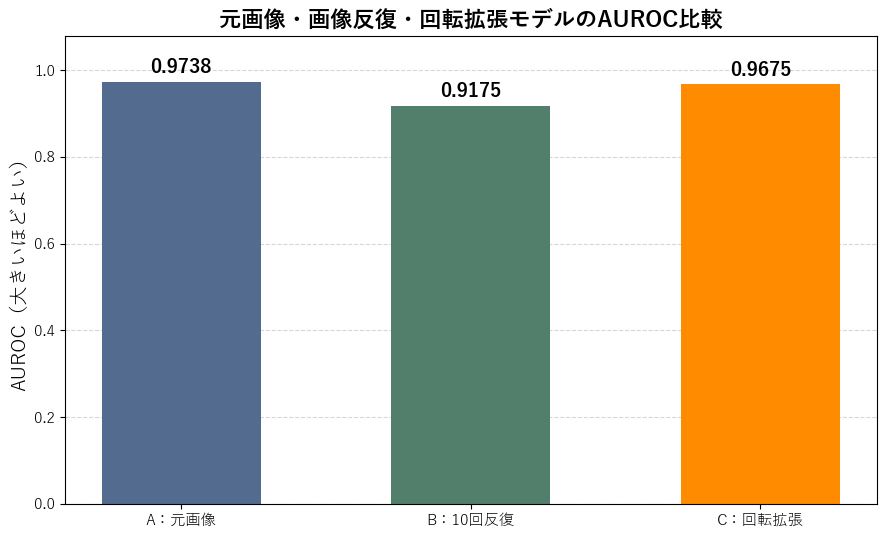

今回の単一シードの比較で最も高いAUROCは **A：元画像：0.9738** です。学習シードを変えたときのばらつきや、有意な優劣はまだ確認していません。

In [5]:
display(comparison[['condition','seed','updates','auroc',
                    'normal_test_sse_per_image','normal_test_mse_per_pixel',
                    'final_train_sse_per_image']].rename(columns={
    'condition':'条件','seed':'学習seed','updates':'更新回数','auroc':'AUROC',
    'normal_test_sse_per_image':'共通正常画像のSSE/画像',
    'normal_test_mse_per_pixel':'共通正常画像のMSE/画素',
    'final_train_sse_per_image':'最終エポックの学習SSE/画像',
}).style.format({'AUROC':'{:.6f}','共通正常画像のSSE/画像':'{:.4f}',
                 '共通正常画像のMSE/画素':'{:.6f}','最終エポックの学習SSE/画像':'{:.4f}'}))

fig, ax = plt.subplots(figsize=(9,5.5))
values = comparison.set_index('condition').loc[list(CONDITIONS),'auroc'].to_numpy()
ax.bar(np.arange(3),values,color=[COLORS[name] for name in CONDITIONS],width=0.55)
ax.set_xticks(np.arange(3),[LABELS[name] for name in CONDITIONS])
ax.set_ylim(0,1.08)
ax.set_yticks(np.linspace(0,1,6))
ax.set_ylabel('AUROC（大きいほどよい）',fontsize=14)
ax.set_title('元画像・画像反復・回転拡張モデルのAUROC比較',fontsize=16,fontweight='bold')
for i,value in enumerate(values):
    ax.text(i,value+0.02,f'{value:.4f}',ha='center',fontsize=14,fontweight='bold')
ax.grid(axis='y',linestyle='--',alpha=0.5)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()
plt.close(fig)

winner = comparison.loc[comparison.auroc.idxmax()]
display(Markdown(f'今回の単一シードの比較で最も高いAUROCは **{LABELS[winner.condition]}：{winner.auroc:.4f}** です。'
                 '学習シードを変えたときのばらつきや、有意な優劣はまだ確認していません。'))

## 5. ROC曲線を重ねて比較する

軸・凡例・グリッドは従来の書式に合わせ、条件の区別のため曲線を青・緑・オレンジにします。曲線上の点は異常スコアの閾値を動かして得られますが、特定の閾値を選ぶ処理は行いません。

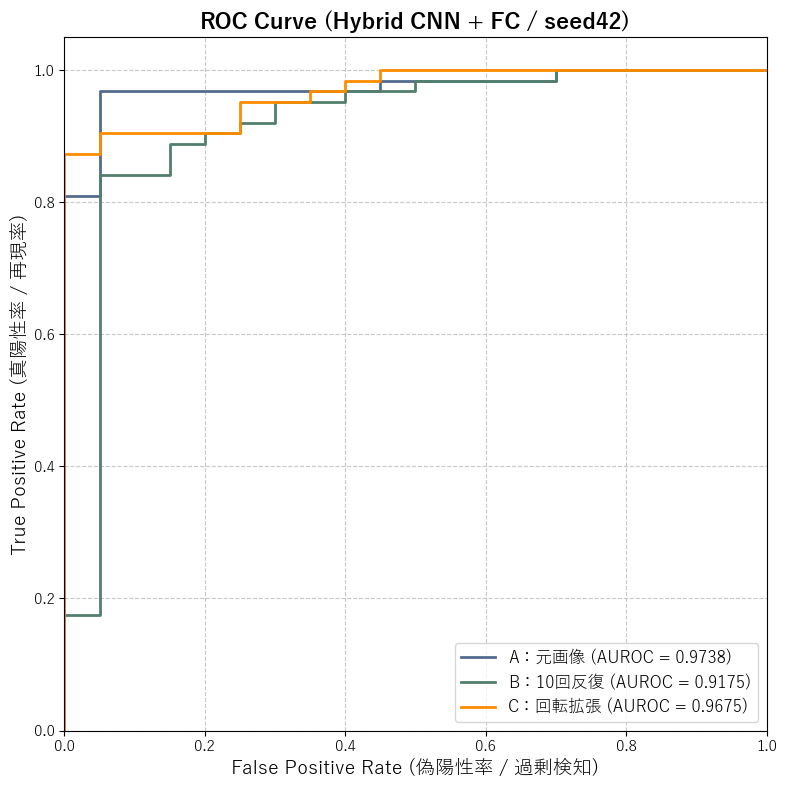

In [6]:
fig, ax = plt.subplots(figsize=(8,8))
for name in CONDITIONS:
    fpr,tpr,_ = binary_roc_curve(image_table.true_label.to_numpy(),all_scores[name])
    auc_value = float(comparison.loc[comparison.condition==name,'auroc'].iloc[0])
    ax.plot(fpr,tpr,color=COLORS[name],lw=2,label=f'{LABELS[name]} (AUROC = {auc_value:.4f})')
ax.set_xlim([0.0,1.0])
ax.set_ylim([0.0,1.05])
ax.set_xlabel('False Positive Rate (偽陽性率 / 過剰検知)',fontsize=14)
ax.set_ylabel('True Positive Rate (真陽性率 / 再現率)',fontsize=14)
ax.set_title('ROC Curve (Hybrid CNN + FC / seed42)',fontsize=16,fontweight='bold')
ax.legend(loc='lower right',fontsize=12)
ax.grid(True,linestyle='--',alpha=0.7)
fig.tight_layout()
plt.show()
plt.close(fig)

## 6. 正常・異常のスコア分布

正常＝緑、異常＝赤のヒストグラムです。3条件で共通の40個のビン境界・同じ横軸範囲・同じ縦軸範囲を使います。今回は固定閾値を設定しないため、閾値の線は表示しません。

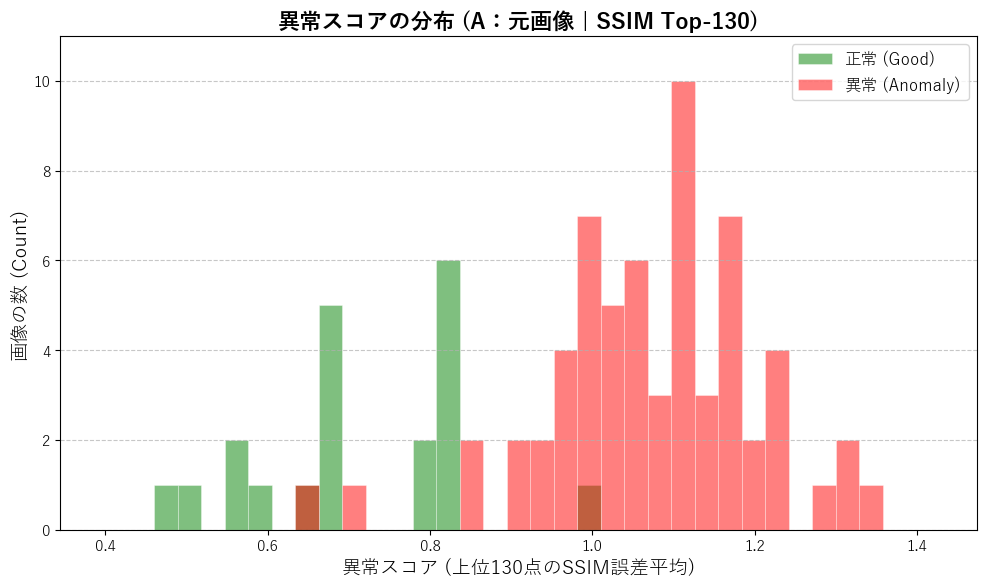

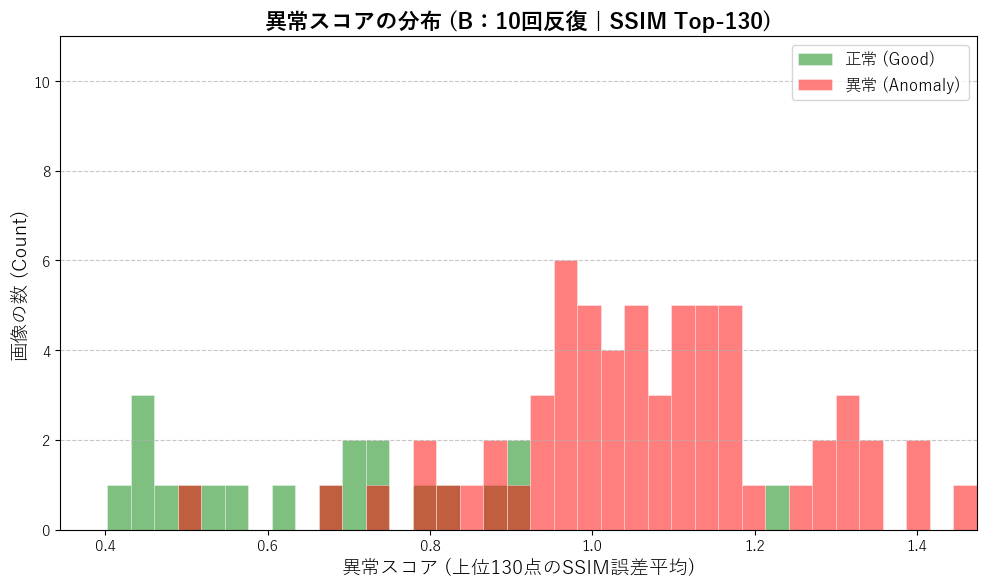

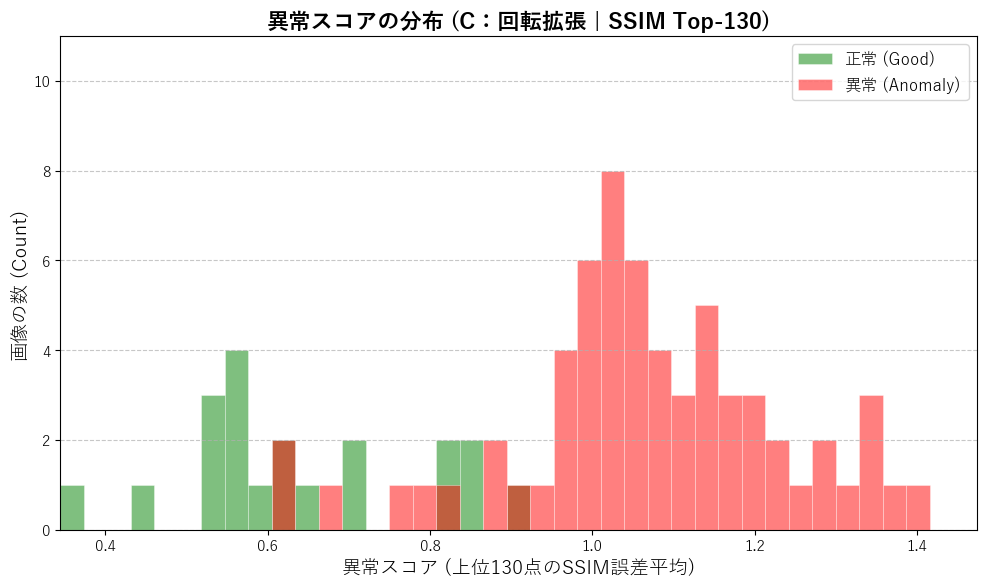

In [7]:
joined_scores = np.concatenate([all_scores[name] for name in CONDITIONS])
common_bins = np.linspace(joined_scores.min(),joined_scores.max(),40)
y = image_table.true_label.to_numpy()
max_count = max(np.histogram(all_scores[name][y==label],bins=common_bins)[0].max()
                for name in CONDITIONS for label in [0,1])
for name in CONDITIONS:
    fig,ax = plt.subplots(figsize=(10,6))
    ax.hist(all_scores[name][y==0],bins=common_bins,color='green',alpha=0.5,
            edgecolor='white',linewidth=0.5,label='正常 (Good)')
    ax.hist(all_scores[name][y==1],bins=common_bins,color='red',alpha=0.5,
            edgecolor='white',linewidth=0.5,label='異常 (Anomaly)')
    ax.set_xlim(common_bins[0],common_bins[-1])
    ax.set_ylim(0,max_count+1)
    ax.set_title(f'異常スコアの分布 ({LABELS[name]} | SSIM Top-{TOP_K})',fontsize=16,fontweight='bold')
    ax.set_xlabel(f'異常スコア (上位{TOP_K}点のSSIM誤差平均)',fontsize=14)
    ax.set_ylabel('画像の数 (Count)',fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(axis='y',linestyle='--',alpha=0.7)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## 7. 全画像のスコアと評価記録

下の表のファイル名は data/bottle/test/ からの相対パスです。評価設定・モデルと画像の識別情報も出力として保存します。

解釈の注意：AとBは更新回数や更新に対するβの進み方が異なります。BとCは保存された初期重み・順序・更新回数が一致していますが、Cの回転処理順は保存設定から確認できません。この1シードの結果を、一般的な回転拡張の効果や高解像度回転の効果として断定しません。

In [8]:
score_table = image_table[['relative_path','category_ja','true_label']].copy()
for name in CONDITIONS:
    score_table[name] = all_scores[name]
display(score_table.rename(columns={'relative_path':'テスト内のファイル','category_ja':'実際の種類',
                                    'true_label':'正解（0正常・1異常）'})
        .style.format({name:'{:.6f}' for name in CONDITIONS}))

evaluation_record = {
    'evaluation_date_jst':'2026-10-22','training_run_id':RUN_ID,'seed':SEED,
    'test_counts':counts,'test_manifest_sha256':manifest_hash,
    'inference':'posterior mean; model.eval(); no sampling',
    'preprocessing':'CenterCrop820 -> Resize128 LANCZOS -> Grayscale -> ToTensor',
    'ssim_window':11,'top_k':TOP_K,'device':str(DEVICE),
    'torch_threads':torch.get_num_threads(),
    'rotation_stage_from_saved_config':rotation_stage,
    'training_config':train_config,
    'metrics':comparison.to_dict('records'),
    'python':platform.python_version(),
    'versions':{v:importlib.metadata.version(v) for v in ['torch','torchvision','numpy','scikit-image','Pillow']},
    'test_manifest':image_records,
}
print(json.dumps(evaluation_record,ensure_ascii=False,indent=2))

,テスト内のファイル,実際の種類,正解（0正常・1異常）,A_original,B_repeat10,C_rotate10
0,broken_large/000.png,大きな破損,1,1.124546,1.316800,1.171950
1,broken_large/001.png,大きな破損,1,1.121376,1.136952,1.135999
2,broken_large/002.png,大きな破損,1,1.236251,1.301096,1.271780
3,broken_large/003.png,大きな破損,1,1.170066,1.179985,1.185281
4,broken_large/004.png,大きな破損,1,1.062790,1.072557,1.054783
5,broken_large/005.png,大きな破損,1,1.106043,1.104328,1.096448
6,broken_large/006.png,大きな破損,1,1.176316,1.180933,1.188607
7,broken_large/007.png,大きな破損,1,1.178466,1.339308,1.227819
8,broken_large/008.png,大きな破損,1,1.160364,1.173254,1.161309
9,broken_large/009.png,大きな破損,1,0.998542,0.967878,0.996881


{
  "evaluation_date_jst": "2026-10-22",
  "training_run_id": "20261021_232232_a54302ed",
  "seed": 42,
  "test_counts": {
    "good": 20,
    "broken_large": 20,
    "broken_small": 22,
    "contamination": 21
  },
  "test_manifest_sha256": "bb7d0f5505f3991b107c0bc1193e0a668a57435903493ed0c9a0957a5ad9fd7e",
  "inference": "posterior mean; model.eval(); no sampling",
  "preprocessing": "CenterCrop820 -> Resize128 LANCZOS -> Grayscale -> ToTensor",
  "ssim_window": 11,
  "top_k": 130,
  "device": "cpu",
  "torch_threads": 4,
  "rotation_stage_from_saved_config": "記録なし：回転時解像度・処理順は未確認",
  "training_config": {
    "experiment": "rotation_control_20261021",
    "run_id": "20261021_232232_a54302ed",
    "seeds": [
      42
    ],
    "epochs": 100,
    "batch_size": 32,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "latent_dim": 64,
    "annealing_epochs": 50,
    "beta_rule": "min(1.0, zero_based_epoch / annealing_epochs)",
    "angles": [
      0,
      36,
      72,
      108,
